In [1]:
import seaborn as sea
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

file_path = "../powercap-calibration.csv"
df = pd.read_csv(file_path)

df

,Program,Powercap,IntelCPU.Temperature_C,IntelCPU.Package_J,System.RunningProcesses_processes,Time.WallClock_ms
0,fibonacci-40,-1,52.50,279.037964,2,16129.9227
1,fibonacci-40,-1,56.00,281.484619,1,16040.7263
2,fibonacci-40,-1,55.25,275.424011,2,16038.1091
3,fibonacci-40,-1,57.50,279.251282,3,16035.3701
4,fibonacci-40,-1,58.25,281.494690,3,16134.4913
...,...,...,...,...,...,...
115,fibonacci-40,15,54.00,253.332336,3,16971.3170
116,fibonacci-40,15,54.25,253.628235,2,16992.5567
117,fibonacci-40,15,53.50,253.275085,2,16964.8321
118,fibonacci-40,15,53.75,253.282715,2,16974.3878


In [2]:
import pandas as pd

def remove_outliers_package(group):
    Q1 = group['IntelCPU.Package_J'].quantile(0.25)
    Q3 = group['IntelCPU.Package_J'].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return group[(group['IntelCPU.Package_J'] >= lower_bound) & (group['IntelCPU.Package_J'] <= upper_bound)]

df_clean = df.groupby(['Program', 'Powercap']).apply(remove_outliers_package).reset_index(drop=True)
df_clean

/tmp/ipykernel_1247632/4292256757.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_clean = df.groupby(['Program', 'Powercap']).apply(remove_outliers_package).reset_index(drop=True)


,Program,Powercap,IntelCPU.Temperature_C,IntelCPU.Package_J,System.RunningProcesses_processes,Time.WallClock_ms
0,fibonacci-40,-1,52.50,279.037964,2,16129.9227
1,fibonacci-40,-1,56.00,281.484619,1,16040.7263
2,fibonacci-40,-1,55.25,275.424011,2,16038.1091
3,fibonacci-40,-1,57.50,279.251282,3,16035.3701
4,fibonacci-40,-1,58.25,281.494690,3,16134.4913
...,...,...,...,...,...,...
103,fibonacci-40,15,54.00,253.332336,3,16971.3170
104,fibonacci-40,15,54.25,253.628235,2,16992.5567
105,fibonacci-40,15,53.50,253.275085,2,16964.8321
106,fibonacci-40,15,53.75,253.282715,2,16974.3878


In [3]:
# Calculate mean of all numeric columns grouped by Program, and Powercap
df_avg = df_clean.groupby(['Program', 'Powercap']).mean().reset_index()
df_avg

,Program,Powercap,IntelCPU.Temperature_C,IntelCPU.Package_J,System.RunningProcesses_processes,Time.WallClock_ms
0,fibonacci-40,-1,56.250000,278.500091,1.600000,16061.877790
1,fibonacci-40,5,38.718750,138.344109,2.500000,27852.503437
2,fibonacci-40,6,39.900000,150.549774,2.500000,25232.875000
3,fibonacci-40,7,41.321429,162.264710,2.000000,23297.331943
4,fibonacci-40,8,43.950000,173.943628,1.400000,21847.559430
5,fibonacci-40,9,45.944444,186.355421,2.111111,20801.278856
6,fibonacci-40,10,47.475000,198.893329,2.200000,19976.374020
7,fibonacci-40,11,48.388889,210.389208,2.333333,19212.582267
8,fibonacci-40,12,50.138889,221.398519,2.222222,18534.401333
9,fibonacci-40,13,51.125000,231.544785,2.375000,17898.090088


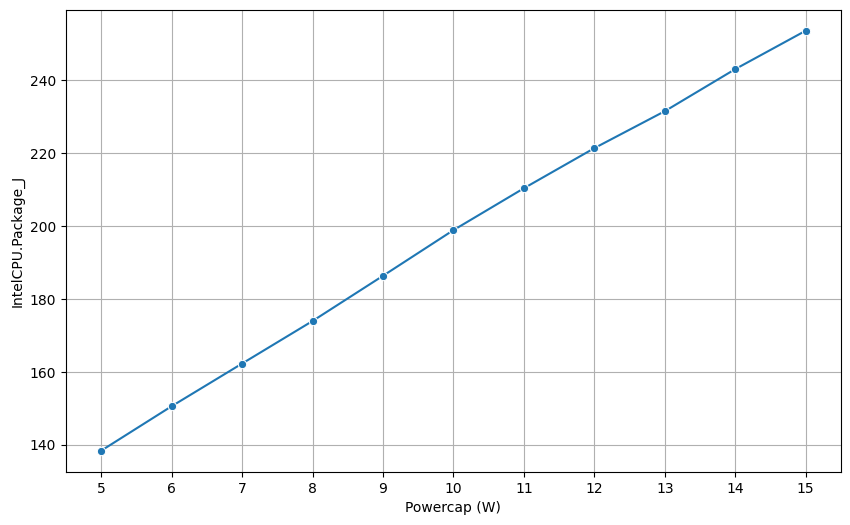

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.lineplot(data=df_avg[df_avg['Powercap'] != -1], x='Powercap', y='IntelCPU.Package_J', marker='o')

plt.title('')
plt.xlabel('Powercap (W)')
plt.ylabel('IntelCPU.Package_J')
plt.grid(True)

plt.xticks(df_avg[df_avg['Powercap'] != -1]['Powercap'].unique())
plt.savefig("powercap-calibration.pdf")
plt.show()
